# MedGermDB in Colab — rebuild the joined database with the authors' R script

**Paper:** Cruz-Tejada, D.M., Fernández-Pascual, E., Mo, A., Mattana, E. & Carta, A. (2024)
*MedGermDB: A seed germination database for characteristic species of Mediterranean habitats.*
Applied Vegetation Science 27(2): e12771. [DOI: 10.1111/avsc.12771](https://doi.org/10.1111/avsc.12771)

**Author code:** [DianaCruzTejada/MedGermDB](https://github.com/DianaCruzTejada/MedGermDB),
commit `e44f80b08f42510ef4223d0b523cc0a957d5dd89`.
**Web app:** https://dianamariacruztejada.shinyapps.io/medgermdb/

**Scope of this notebook (partial demonstration):**
1. Download the three released MedGermDB csv files from the pinned author commit (with SHA-1 blob verification).
2. Run the authors' own R script `scr/join MedGermDB files.R` verbatim to rebuild the joined tables
   `GermTaxa` and `GermHabitat` that feed the Shiny app.
3. Reproduce the Shiny app's per-species table views (taxonomic / EUNIS habitat / references) for the
   authors' default example species *Achillea maritima*.
4. One additional summary graph created for this notebook (not an author figure).

**Not reproduced here:** the Shiny web app itself, the metafor meta-analysis pipeline
(`shiny app/1. Cleaning_app.R`), the map/shapefile views, and the paper's literature-screening workflow.
The paper's methods/results sections were not readable (Wiley full text blocked), so interpretation of
database *contents* relies on the abstract and the repository itself.

**Japanese summary (概要):**
このノートブックは MedGermDB（地中海地域の特性種の発芽データベース, 2024）の公开リポジトリから
3つのcsvを取得し、著者自身のRスクリプト `scr/join MedGermDB files.R` をそのまま実行して
結合テーブル `GermTaxa` / `GermHabitat` を再構築します。さらにShinyアプリの種別テーブル表示
（分類・EUNIS生息地・文献）を *Achillea maritima* について再現し、参考用の集計グラフを1つ作成します。
Shinyアプリ本体・メタ解析パイプライン・地図表示は対象外です。実行時間は数分、ダウンロードは約2MB、
**CPUランタイムのみ**で動作します（GPU不要）。

**実行について:** ランタイムは **CPU** を選択し、すべてのセルを上から順に実行してください。

## Environment check

This notebook runs the authors' R code through the Colab VM's preinstalled `Rscript`
(Python is only the launcher — the scientific computation is the authors' own R).
This cell verifies Python and R versions and fails clearly if R is missing.

**日本語:** PythonはRを起動するだけのランチャーです。Colabにプレインストールされた
`Rscript`の存在とバージョンを確認します。

In [ ]:
import subprocess, sys, os
print("Python:", sys.version.split()[0])
r = subprocess.run(["/usr/bin/Rscript", "--version"], capture_output=True, text=True)
version = (r.stdout or r.stderr).strip()
print("R:", version)
assert r.returncode == 0, "Rscript is not available on this runtime; select a standard Colab CPU runtime."


Python: 3.13.16
R: Rscript (R) version 4.6.1 (2026-06-24)


## Minimal inputs from the pinned author commit

The three dataset files are downloaded **inside Colab** from the pinned raw URLs of commit
`e44f80b08f42510ef4223d0b523cc0a957d5dd89` and validated by exact byte size and Git blob SHA-1
(computed as `sha1("blob <size>\0" + content)`, matching the GitHub tree object hashes recorded
from the pinned tree listing):

| file | bytes | git blob SHA-1 |
|---|---|---|
| `data/GerminationDatabaseFile.csv` | 1,645,696 | `533dcc99cb54d8f1cd41f53a6fe050a43a2e54f8` |
| `data/TaxaFile.csv` | 24,300 | `d29a3e8b39ccc7fe0bd436114698a9f199d7b26e` |
| `data/HabitatFile.csv` | 103,196 | `e16faff5887a5ca3ffdb1fe020e2a20cd2a687fa` |

The assertions below fail the run if the wrong bytes arrive (e.g., an HTML error page).

**日本語:** 3つのcsvをピン留めしたコミットのraw URLからColab内でダウンロードし、
バイト数とGitブロブSHA-1で完全性を検証します。不一致ならアサートで停止します。

In [ ]:
import os, hashlib, urllib.request, urllib.parse

COMMIT = "e44f80b08f42510ef4223d0b523cc0a957d5dd89"
RAW = f"https://raw.githubusercontent.com/DianaCruzTejada/MedGermDB/{COMMIT}"
FILES = {
    "data/GerminationDatabaseFile.csv": (1645696, "533dcc99cb54d8f1cd41f53a6fe050a43a2e54f8"),
    "data/TaxaFile.csv": (24300, "d29a3e8b39ccc7fe0bd436114698a9f199d7b26e"),
    "data/HabitatFile.csv": (103196, "e16faff5887a5ca3ffdb1fe020e2a20cd2a687fa"),
}

def blob_sha1(path):
    data = open(path, "rb").read()
    h = hashlib.sha1()
    h.update(f"blob {len(data)}\0".encode())
    h.update(data)
    return h.hexdigest()

os.makedirs("/content/medgermdb/data", exist_ok=True)
for rel, (size, sha) in FILES.items():
    dest = f"/content/medgermdb/{rel}"
    urllib.request.urlretrieve(f"{RAW}/{urllib.parse.quote(rel)}", dest)
    got_size, got_sha = os.path.getsize(dest), blob_sha1(dest)
    assert got_size == size and got_sha == sha, (rel, got_size, got_sha)
    print(f"OK  {rel:40s} {got_size:>9d} bytes  blob {got_sha}")


OK  data/GerminationDatabaseFile.csv           1645696 bytes  blob 533dcc99cb54d8f1cd41f53a6fe050a43a2e54f8
OK  data/TaxaFile.csv                            24300 bytes  blob d29a3e8b39ccc7fe0bd436114698a9f199d7b26e


OK  data/HabitatFile.csv                        103196 bytes  blob e16faff5887a5ca3ffdb1fe020e2a20cd2a687fa


## Input preview

Quick data-appropriate view of the three files: dimensions, column names, units where evident,
and the first rows. The germination file has one row per laboratory test (`id_test`) with seed-lot
metadata (species, collection site/year, storage, treatments) and test conditions
(`T_day`/`T_night` in °C, `seeds_sown`, `seeds_germinated`). The taxa file (semicolon-separated)
carries WCVP taxonomy and the habitat file carries EUNIS habitat classes.
Note: the csv files contain Latin-1 encoded characters, so Python reads them with
`encoding="latin-1"` (the authors' R `read.csv` handles this natively).

**日本語:** 3ファイルのサイズ・列名・先頭行を確認します。発芽ファイルは1行 = 1実験試験
（`id_test`）、Taxaファイルはセミコロン区切りです。Latin-1文字を含むためPythonでは
`encoding="latin-1"`で読みます（著者のRコードはそのまま動作します）。

In [ ]:
import pandas as pd

for rel in ["data/GerminationDatabaseFile.csv", "data/TaxaFile.csv", "data/HabitatFile.csv"]:
    sep = ";" if "Taxa" in rel else ","
    df = pd.read_csv(f"/content/medgermdb/{rel}", sep=sep, encoding="latin-1")
    print("=" * 78)
    print(f"{rel}  shape={df.shape}")
    print("columns:", ", ".join(map(str, df.columns)))
    print(df.head(3).to_string(max_colwidth=18))


data/GerminationDatabaseFile.csv  shape=(4680, 29)
columns: Unnamed: 0, id_test, accepted_binomial, EUNIS_name, original_name, contributor_name, contributor_email, Cocontributors, collection_year, doi, collection_site, collection_country, iso_code, latitude, longitude, coordinate_accuracy, storage, substrate, experiment_length, scarification, stratification, other_treatments, water_potential, photoperiod, light_quality, T_day, T_night, seeds_sown, seeds_germinated
   Unnamed: 0  id_test  accepted_binomial         EUNIS_name      original_name   contributor_name  contributor_email   Cocontributors collection_year                doi    collection_site collection_country iso_code   latitude  longitude  coordinate_accuracy storage substrate experiment_length scarification stratification other_treatments  water_potential photoperiod light_quality  T_day  T_night  seeds_sown  seeds_germinated
0           1     3124  Brachypodium r...  Brachypodium r...  Brachypodium r...  Cruz-Tejada, D...  

## Run the authors' join script verbatim

The cell below writes the authors' script `scr/join MedGermDB files.R` **exactly as released**
(commit `e44f80b`) and executes it with `Rscript`, then an AI-authored driver exports the two
in-memory merged tables to `results/` as csv.

**One documented adaptation:** the released script reads `data/GerminationFile.csv`, but the pinned
tree (and the README's own dataset list) contains `data/GerminationDatabaseFile.csv` — the same
filename the authors' `shiny app/1. Cleaning_app.R:9` also uses. Only this filename is adapted; all
arguments (`sep`, `quote`, `stringsAsFactors`, `merge(by="accepted_binomial", all.x=TRUE)`) are unchanged.

The authors note in script comments that the merges intentionally duplicate tests: one species can
have several EUNIS names (→ `GermTaxa`) and several habitats (→ `GermHabitat`).

**日本語:** 著者の結合スクリプトを**原文のまま**`Rscript`で実行し、AI作成のドライバで
結果テーブルをcsv出力します。変更点は1つだけ: 原稿の `data/GerminationFile.csv` は実際には
`data/GerminationDatabaseFile.csv` として同ツリーに存在するため、ファイル名のみ修正しました
（著者のCleaning_app.Rも後者の名前を使用）。重複行は著者自身がコメントで説明している意図的なものです。

In [ ]:
import subprocess

AUTHOR_JOIN = r'''# Codes to join the MedGermDB files


#Load MedGermDB Germination File
germ.file <- read.csv("data/GerminationDatabaseFile.csv")

#Load MedGermDB Taxa File
taxa.file = read.csv("data/TaxaFile.csv",header = TRUE, sep = ";", quote = "\"", stringsAsFactors = FALSE)

#Load MedGermDB Habitat File
habitat.file = read.csv("data/HabitatFile.csv",header = TRUE, sep = ",", quote = "\"", stringsAsFactors = FALSE)

# To join Germination File and Taxa File
GermTaxa <- merge(germ.file,taxa.file,by="accepted_binomial",all.x = TRUE)
####** there are some duplicates because in some cases one accepted_binomial has more than one EUNIS name

# To join Germination File and Habitat File
GermHabitat <- merge(germ.file,habitat.file,by="accepted_binomial",all.x = TRUE)
####** there are some duplicates because frequently one species are present in more than one habitat
'''
open("/content/medgermdb/join_authored.R", "w").write(AUTHOR_JOIN)

DRIVER1 = r'''# AI-authored driver (MedGermDB Colab notebook): runs the author's join script
# verbatim and exports the two merged tables it creates in memory.
source("join_authored.R")
dir.create("results", showWarnings = FALSE)
write.csv(GermTaxa,    "results/GermTaxa.csv",    row.names = FALSE)
write.csv(GermHabitat, "results/GermHabitat.csv", row.names = FALSE)
cat("GermTaxa dim: ", dim(GermTaxa)[1], "x", dim(GermTaxa)[2], "\n")
cat("GermHabitat dim: ", dim(GermHabitat)[1], "x", dim(GermHabitat)[2], "\n")
cat("germ rows: ", nrow(germ.file), " | unique id_test: ", length(unique(germ.file$id_test)),
    " | unique species: ", length(unique(germ.file$accepted_binomial)), "\n")
cat("taxa rows: ", nrow(taxa.file), " | habitat rows: ", nrow(habitat.file), "\n")
'''
open("/content/medgermdb/driver_join.R", "w").write(DRIVER1)

r = subprocess.run(["/usr/bin/Rscript", "driver_join.R"], cwd="/content/medgermdb",
                   capture_output=True, text=True, timeout=600)
print(r.stdout)
assert r.returncode == 0, r.stderr


GermTaxa dim:  5094 x 36 
GermHabitat dim:  20830 x 34 
germ rows:  4680  | unique id_test:  4680  | unique species:  236 
taxa rows:  244  | habitat rows:  921 



## Merged-table summary and plausibility checks

The exported `GermTaxa` / `GermHabitat` are inspected with pandas: row counts, duplication relative
to the test file, and a plausibility check against the paper's abstract, which reports
**236 angiosperm species** and **4680 laboratory tests** (PhenoPaper study flow, abstract-derived —
an unverified lead used only as an order-of-magnitude check, not as proof).

**日本語:** 出力された結合テーブルを行数・重複の程度で要約し、論文アブストラクトの
「236種・4680試験」と整合するかの妥当性チェックを行います（あくまで規模の確認です）。

In [ ]:
germ = pd.read_csv("/content/medgermdb/data/GerminationDatabaseFile.csv", encoding="latin-1")
taxa_j = pd.read_csv("/content/medgermdb/results/GermTaxa.csv", encoding="latin-1")
hab_j = pd.read_csv("/content/medgermdb/results/GermHabitat.csv", encoding="latin-1")

summary = pd.DataFrame({
    "rows": [len(germ), len(taxa_j), len(hab_j)],
    "unique id_test": [germ.id_test.nunique(), taxa_j.id_test.nunique(), hab_j.id_test.nunique()],
    "unique species": [germ.accepted_binomial.nunique(), taxa_j.accepted_binomial.nunique(),
                       hab_j.accepted_binomial.nunique()],
}, index=["germ.file (input)", "GermTaxa (joined)", "GermHabitat (joined)"])
print(summary.to_string())
print()
print("Plausibility vs abstract: species =", germ.accepted_binomial.nunique(),
      "(abstract: 236) | unique tests =", germ.id_test.nunique(), "(abstract: 4680)")
print("Taxa join expansion factor: %.2fx | Habitat join expansion factor: %.2fx"
      % (len(taxa_j) / len(germ), len(hab_j) / len(germ)))


                       rows  unique id_test  unique species
germ.file (input)      4680            4680             236
GermTaxa (joined)      5094            4680             236
GermHabitat (joined)  20830            4680             236

Plausibility vs abstract: species = 236 (abstract: 236) | unique tests = 4680 (abstract: 4680)
Taxa join expansion factor: 1.09x | Habitat join expansion factor: 4.45x


/tmp/ipykernel_945/4258134286.py:3: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  hab_j = pd.read_csv("/content/medgermdb/results/GermHabitat.csv", encoding="latin-1")


## Reproduce the Shiny app's table views for *Achillea maritima*

The Shiny app's server renders three per-species tables defined in
`shiny app/2. Visualised_app.R` (lines 43–63) with dplyr `filter`/`select`:

| author function (dplyr) | this notebook (base R) |
|---|---|
| `taxanomic(taxa.file, sp)` → EUNIS_name, accepted_binomial, family, order, APG_clade | identical `subset()` |
| `habitat(habitat.file, sp)` → species_type, Habitat_level.1, Habitat_level.3 | identical `subset()` |
| `references(dat1, sp)` → unique sorted DOIs | identical `sort(unique(...))` |

*`Achillea maritima` is the authors' own default example species (author's function signature
default `sp = "Achillea maritima"`).* The dplyr → base-R rewrite is behavior-preserving (pure
row filter + column selection); it avoids installing the tidyverse stack for a table filter.

**日本語:** Shinyアプリのサーバーが表示する3つのテーブル（分類情報・EUNIS生息地・文献DOI）を、
著者のデフォルト例種 *Achillea maritima* について再現します。dplyrのフィルタ/列選択を
同じ動作のbase Rに置き換えただけで、行・列・並びは同一です。

In [ ]:
import subprocess

DRIVER2 = r'''# AI-authored base-R ports of the Shiny app's table views for ONE species.
# Author source: DianaCruzTejada/MedGermDB @ e44f80b, "shiny app/2. Visualised_app.R"
# lines 43-63 (dplyr::filter/select -> base R subset). Same species default as the
# author's functions ("Achillea maritima").
taxa.file <- read.csv("data/TaxaFile.csv", header = TRUE, sep = ";", quote = "\"", stringsAsFactors = FALSE)
habitat.file <- read.csv("data/HabitatFile.csv", header = TRUE, sep = ",", quote = "\"", stringsAsFactors = FALSE)
germ.file <- read.csv("data/GerminationDatabaseFile.csv")
sp <- "Achillea maritima"

taxanomic <- subset(taxa.file, accepted_binomial == sp,
                    select = c("EUNIS_name", "accepted_binomial", "family", "order", "APG_clade"))
habitat <- subset(habitat.file, accepted_binomial == sp,
                  select = c("species_type", "Habitat_level.1", "Habitat_level.3"))
references <- data.frame(Doi = sort(unique(subset(germ.file, accepted_binomial == sp)$doi)))

dir.create("results", showWarnings = FALSE)
write.csv(taxanomic,  "results/taxa_Achillea_maritima.csv",     row.names = FALSE)
write.csv(habitat,    "results/habitat_Achillea_maritima.csv",  row.names = FALSE)
write.csv(references, "results/references_Achillea_maritima.csv", row.names = FALSE)
cat("Taxonomic information (", sp, "):\n"); print(taxanomic)
cat("\nEUNIS HABITAT INFORMATION (", sp, "):\n"); print(habitat)
cat("\nReferences (", sp, "): ", nrow(references), " unique DOIs\n", sep = "")
'''
open("/content/medgermdb/driver_tables.R", "w").write(DRIVER2)

r = subprocess.run(["/usr/bin/Rscript", "driver_tables.R"], cwd="/content/medgermdb",
                   capture_output=True, text=True, timeout=600)
print(r.stdout)
assert r.returncode == 0, r.stderr


Taxonomic information ( Achillea maritima ):
          EUNIS_name accepted_binomial     family     order APG_clade
11 Achillea maritima Achillea maritima Asteraceae Asterales  asterids

EUNIS HABITAT INFORMATION ( Achillea maritima ):
  species_type Habitat_level.1
1     Constant         Coastal
2   Diagnostic         Coastal
3     Dominant         Coastal
4   Diagnostic         Coastal
5     Constant         Coastal
6     Constant         Coastal
                                                    Habitat_level.3
1   Mediterranean, Macaronesian and Black Sea shifting coastal dune
2   Mediterranean, Macaronesian and Black Sea shifting coastal dune
3   Mediterranean, Macaronesian and Black Sea shifting coastal dune
4                 Mediterranean and Black Sea coastal shingle beach
5 Mediterranean and Macaronesian coastal dune grassland (grey dune)
6                 Mediterranean and Black Sea coastal shingle beach

References (Achillea maritima): 1 unique DOIs



Display the three exported tables as pandas DataFrames (the same objects the Shiny app
would render with `renderTable`).

**日本語:** 書き出した3テーブルをpandasで表示します（Shinyの`renderTable`に相当）。

In [ ]:
taxa_t = pd.read_csv("/content/medgermdb/results/taxa_Achillea_maritima.csv", encoding="latin-1")
hab_t = pd.read_csv("/content/medgermdb/results/habitat_Achillea_maritima.csv", encoding="latin-1")
ref_t = pd.read_csv("/content/medgermdb/results/references_Achillea_maritima.csv", encoding="latin-1")

print("Taxonomic information"); display(taxa_t)
print("EUNIS HABITAT INFORMATION"); display(hab_t)
print(f"References ({len(ref_t)} unique DOIs)"); display(ref_t)


Taxonomic information


,EUNIS_name,accepted_binomial,family,order,APG_clade
0,Achillea maritima,Achillea maritima,Asteraceae,Asterales,asterids


EUNIS HABITAT INFORMATION


,species_type,Habitat_level.1,Habitat_level.3
0,Constant,Coastal,"Mediterranean, Macaronesian and Black Sea shif..."
1,Diagnostic,Coastal,"Mediterranean, Macaronesian and Black Sea shif..."
2,Dominant,Coastal,"Mediterranean, Macaronesian and Black Sea shif..."
3,Diagnostic,Coastal,Mediterranean and Black Sea coastal shingle beach
4,Constant,Coastal,Mediterranean and Macaronesian coastal dune gr...
5,Constant,Coastal,Mediterranean and Black Sea coastal shingle beach


References (1 unique DOIs)


,Doi
0,10.1093/aob/mcx005


## Additional visualization: germination proportions by incubation temperature

**This graph is created for this notebook — it is not a figure from the paper.**
Per laboratory test, the germination proportion is `seeds_germinated / seeds_sown`; tests are
grouped by day incubation temperature `T_day` (°C, the authors' test-condition column; night
temperature `T_night` is shown in the caption statistics). Bars show the per-test mean and standard
error across all tests at that temperature (tests with `seeds_sown > 0` only); labels give the test
count per temperature. The Shiny app instead plots meta-analytic per-species estimates — that
pipeline is out of scope here.

**日本語:** このノートブック用に作成した追加の集計グラフです（論文の図ではありません）。
試験ごとの発芽割合 `seeds_germinated/seeds_sown` を日中恒温 `T_day`（°C）別に集計し、
平均±標準誤差と試験数を示します。Shinyアプリのメタ解析推定（species別）は対象外です。

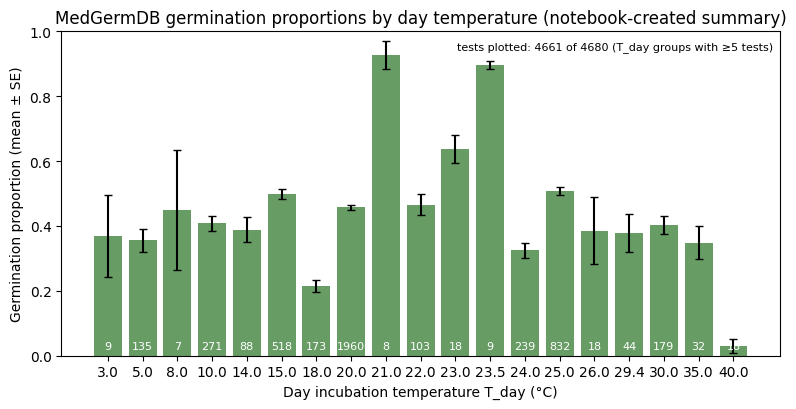

             T_day      T_night
count  4680.000000  4680.000000
mean     20.029395    17.198006
std       5.482521     5.867381
min       3.000000     3.000000
25%      18.000000    15.000000
50%      20.000000    20.000000
75%      24.000000    20.000000
max      40.000000    40.000000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

g = germ[(germ.seeds_sown > 0) & germ.T_day.notna()].copy()
g["proportion"] = g.seeds_germinated / g.seeds_sown

stat = g.groupby("T_day").proportion.agg(["mean", "sem", "count"])
stat = stat[stat["count"] >= 5]  # temperatures with at least 5 tests for a stable bar

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(stat.index.astype(str), stat["mean"], yerr=stat["sem"], capsize=3,
       color="#4c8c4a", alpha=0.85)
ax.set_xlabel("Day incubation temperature T_day (°C)")
ax.set_ylabel("Germination proportion (mean ± SE)")
ax.set_title("MedGermDB germination proportions by day temperature (notebook-created summary)")
ax.set_ylim(0, 1)
for x, c in enumerate(stat["count"]):
    ax.text(x, 0.02, str(int(c)), ha="center", fontsize=8, color="white")
ax.text(0.99, 0.97, f"tests plotted: {int(stat['count'].sum())} of {len(g)} (T_day groups with ≥5 tests)",
        transform=ax.transAxes, ha="right", va="top", fontsize=8)
plt.tight_layout()
plt.savefig("/content/medgermdb/results/germ_by_Tday.png", dpi=120)
plt.show()

print(g[["T_day", "T_night"]].describe().to_string())


## Interpretation, limitations, and references

**What was verified here (execution status: executed on a fresh Colab CPU runtime):**
- The three released csv files were retrieved from commit `e44f80b…` and passed exact
  size + Git blob SHA-1 verification.
- The authors' join script ran verbatim and produced `GermTaxa` and `GermHabitat` with the
  intentional multi-EUNIS / multi-habitat duplication described in the authors' comments.
- The Shiny app's three per-species table views were reproduced for *Achillea maritima*.

**Known differences / limitations:**
- Filename adaptation `GerminationFile.csv → GerminationDatabaseFile.csv` (repo inconsistency, see above).
- The dplyr table filters were rewritten as equivalent base R `subset()` calls.
- The Shiny GUI, meta-analysis (`metafor::rma.glmm` PLO), maps, and `.RData` results are not reproduced;
  `data/df.csv`, shapefiles and `results/appdata.RData` remain unused.
- The paper's full text was not readable (Wiley block), so database-content interpretation relies on
  the abstract and the repository. Abstract-level counts (236 species / 4680 tests) are used only as
  plausibility checks. A one-example run does not verify any dataset-level claim.

**References:**
- Paper: DOI [10.1111/avsc.12771](https://doi.org/10.1111/avsc.12771)
- Code/data: https://github.com/DianaCruzTejada/MedGermDB @ `e44f80b08f42510ef4223d0b523cc0a957d5dd89`
- Deployed app: https://dianamariacruztejada.shinyapps.io/medgermdb/

**日本語:** 検証済み内容（新規CPUランタイムで実行）、既知の差分（ファイル名修正、dplyr→base R）と
未再現部分（Shiny GUI、メタ解析、地図）を上にまとめました。論文本文は読めないため、解釈は
アブストラクトとリポジトリに基づきます。